# 📌 Bölüm 0: Başlangıç Notları ve Hızlı Uygulamalar (Orijinal Kodlar)
Aşağıdaki kod hücreleri Log-Normal Dağılım için hazırlanan ilk notları, PDF çizimini, SciPy rvs örneklem üretimini ve logaritma dönüşümünü içermektedir.


In [9]:
# Log Normal Distribituion
# Logaritma normal dağılım gösteren olasılık dağılım fonksiyondur.

# Toplumdaki maaş dağılımı
# Hisse senetleri fiyatları
# İnsan ömrü

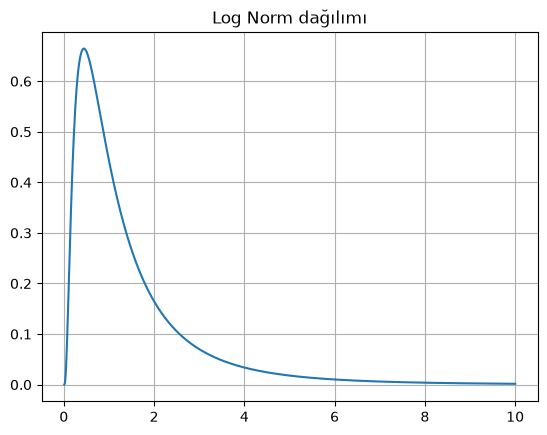

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import lognorm

mean = 0
std = 0.9

x = np.linspace(0.01,10,1000)
pdf = lognorm.pdf(x, s = std, scale = np.exp(mean))

plt.plot(x,pdf)
plt.title("Log Norm dağılımı")
plt.grid(True)
plt.show()

In [11]:
samples = lognorm.rvs(s = std, scale = np.exp(mean), size = 1000)
samples

array([ 1.81124449,  3.01940293,  3.31124306,  0.9792677 ,  0.88366994,
        1.65709755,  1.80513393,  0.71990112,  0.25286904,  1.55959039,
        2.89539717,  1.99792354,  0.23285972,  0.88622062,  1.17539632,
        2.3677238 ,  1.79955566,  0.7430323 ,  3.48560681,  2.00151415,
        1.01577623,  2.42873385,  1.21721423,  3.07955799,  0.57292429,
        1.61434339,  0.15586105,  0.66543188,  1.23509081,  1.21295773,
        0.2158888 ,  1.01861743,  0.47378624,  2.11093903,  1.10340299,
        5.2527034 ,  0.96087584,  5.92116967,  0.70989514,  2.92280708,
        4.03846434,  6.26199168,  1.78693257,  0.29481891,  0.94105916,
        1.24683859,  2.56275816,  0.34665553,  0.14895605,  0.81146904,
        1.4763673 ,  1.43959264,  0.2648043 ,  0.9890459 ,  0.30516098,
        3.58204517,  0.47609821,  0.65194986,  0.28070952,  0.90275857,
        0.05182961,  0.42772493,  0.42796672,  0.97011525,  0.67258326,
        1.77039403,  1.60510649,  2.70679123,  2.22255449,  0.71

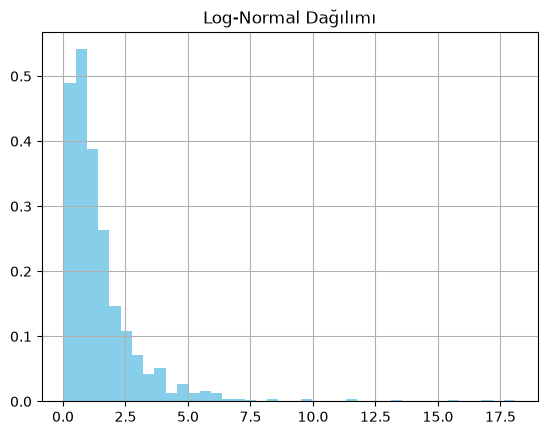

In [12]:
plt.hist(samples,bins = 40, density = True, color = "skyblue")
plt.title("Log-Normal Dağılımı")
plt.grid(True)
plt.show()

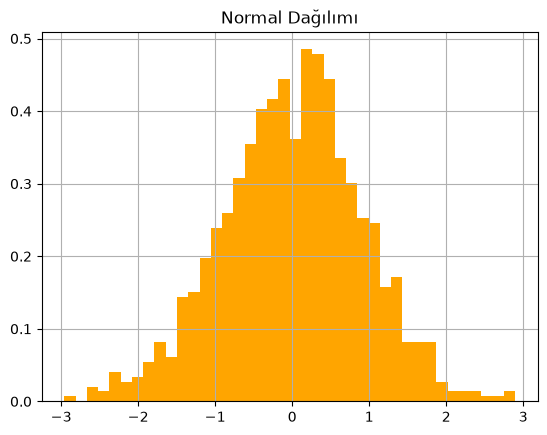

In [13]:
norm_samples = np.log(samples)
plt.hist(norm_samples, bins = 40, density= True, color = "orange")
plt.title("Normal Dağılımı")
plt.grid(True)
plt.show()

---
# 📚 LOG-NORMAL DAĞILIM (LOG-NORMAL DISTRIBUTION)
### Pozitif Çarpık Veriler ve Çarpımsal Süreçler - Kapsamlı Teori ve Uygulama Rehberi

---

## 📌 1. Giriş ve Sezgisel Açıklama

**Log-Normal Dağılım (Log-Normal Distribution)**, doğal dünyada, ekonomide, finansta ve mühendislikte karşımıza çıkan **en önemli pozitif çarpık (right-skewed)** sürekli olasılık dağılımlarından biridir.

### 🌟 Temel Tanım:
> Bir $X$ rastgele değişkeninin doğal logaritması $\ln(X)$ **Normal (Gauss)** dağılıyorsa, $X$ değişkeninin kendisine **Log-Normal Dağılıma** sahiptir denir:
> $$Y = \ln(X) \sim \mathcal{N}(\mu, \sigma^2) \iff X = e^Y \sim \text{Log-Normal}(\mu, \sigma^2)$$

---

### 🔄 Toplamsal (Additive) vs. Çarpımsal (Multiplicative) Süreçler

| Süreç Tipi | Mekanizma | Oluşan Dağılım | Örnekler |
| :--- | :--- | :--- | :--- |
| **Toplamsal Süreç** | Birbirine eklenen bağımsız etkiler: $X = X_1 + X_2 + \dots + X_n$ | **Normal (Gauss)** (CLT gereği) | İnsan boyu, ölçüm hataları, fabrika toleransı |
| **Çarpımsal Süreç** | Birbirini katlayan bağımsız yüzdesel etkiler: $X = X_1 \times X_2 \times \dots \times X_n$ | **Log-Normal** (Çarpımsal CLT) | Şirket gelirleri, hisse senedi fiyatları, hücre bölünmesi |

### 💡 Neden Log-Normal Dağılım?
1. **Asla Negatif Olamaz ($X > 0$):** Maaşlar, hisse senedi fiyatları, web sitesi yanıt süreleri veya biyolojik hücre boyutları asla negatif olamaz.
2. **Sağa Çarpıklık:** Çoğu veri küçük/orta değerlerde kümelenirken, az sayıda ekstrem büyük değer (örneğin süper zenginler, viralleşen içerikler) sağa doğru uzun bir kuyruk oluşturur.


---
## 📐 2. Matematiksel Formülasyon ve İstatistiksel Momentler

$X \sim \text{Log-Normal}(\mu, \sigma^2)$ olmak üzere ($\mu \in \mathbb{R}$, $\sigma > 0$):
*(Buradaki $\mu$ ve $\sigma$, $X$'in değil, $\ln(X)$'in ortalaması ve standart sapmasıdır!)*

### 1. Olasılık Yoğunluk Fonksiyonu (PDF):
$$f(x; \mu, \sigma) = \frac{1}{x \sigma \sqrt{2\pi}} \exp\left( -\frac{(\ln x - \mu)^2}{2\sigma^2} \right), \quad x > 0$$

### 2. Kümülatif Dağılım Fonksiyonu (CDF):
$$F(x; \mu, \sigma) = \Phi\left( \frac{\ln x - \mu}{\sigma} \right) = \frac{1}{2} \left[ 1 + \text{erf}\left( \frac{\ln x - \mu}{\sigma \sqrt{2}} \right) \right], \quad x > 0$$

### 3. Kritik İstatistiksel Momentler (Sıralama: Mod < Medyan < Ortalama):
- **Mod (En Yüksek Olasılıklı Değer / Zirve):**
  $$\text{Mod}[X] = e^{\mu - \sigma^2}$$
- **Medyan (Veriyi %50-%50 Bölen Orta Değer):**
  $$\text{Medyan}[X] = e^\mu$$
- **Beklenen Değer (Aritmetik Ortalama):**
  $$E[X] = e^{\mu + \frac{\sigma^2}{2}}$$
- **Varyans:**
  $$\text{Var}(X) = (e^{\sigma^2} - 1) e^{2\mu + \sigma^2}$$
- **Çarpıklık (Skewness):**
  $$\gamma_1 = (e^{\sigma^2} + 2)\sqrt{e^{\sigma^2} - 1} > 0 \quad (\text{Daima pozitif / Sağa çarpık})$$

> ⚠️ **SciPy Parametre Eşleşmesi:**
> `scipy.stats.lognorm` kütüphanesinde parametreler şöyle tanımlanır:
> - `s` = $\sigma$ (şekil parametresi / shape)
> - `scale` = $e^\mu$ (ölçek parametresi / scale = `np.exp(mu)`)


---
## 💻 3. Python Ortam Hazırlığı ve Kütüphaneler


In [ ]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Görselleştirme ve stil ayarları
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

np.random.seed(42)
print("✅ Gerekli kütüphaneler başarıyla yüklendi ve grafik ortamı hazırlandı.")


---
## 🎨 4. Parametre Duyarlılık Analizi: $\mu$ ve $\sigma$'nın Eğriye Etkisi

- **$\sigma$ (Şekil / Shape):** Değer büyüdükçe dağılımın sağ kuyruğu uzar, çarpıklık katlanarak artar.
- **$\mu$ (Ölçek / Scale):** Dağılımın merkezini sağa doğru genişletir.
- **Mod, Medyan ve Ortalama İlişkisi:** Sağa çarpık dağılımlarda daima $\text{Mod} < \text{Medyan} < \text{Ortalama}$ kuralı geçerlidir.


In [ ]:
x_vals = np.linspace(0.01, 8.0, 1000)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Farklı sigma değerleri (mu = 0 sabit)
mu_fixed = 0.0
sigmas = [0.25, 0.5, 0.8, 1.2]
colors = ['#2980b9', '#27ae60', '#e67e22', '#e74c3c']

for sigma, color in zip(sigmas, colors):
    pdf = stats.lognorm.pdf(x_vals, s=sigma, scale=np.exp(mu_fixed))
    axes[0].plot(x_vals, pdf, label=f'σ = {sigma}', color=color, linewidth=2)

axes[0].set_title("Farklı σ Değerleri (μ = 0 Sabit)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("x", fontsize=11)
axes[0].set_ylabel("Olasılık Yoğunluğu f(x)", fontsize=11)
axes[0].set_ylim(0, 2.0)
axes[0].legend(fontsize=10)

# 2. Tek Bir Eğri Üzerinde Mod, Medyan ve Ortalama Gösterimi (mu = 0.5, sigma = 0.7)
mu_demo = 0.5
sigma_demo = 0.7
x_demo = np.linspace(0.01, 10.0, 1000)
pdf_demo = stats.lognorm.pdf(x_demo, s=sigma_demo, scale=np.exp(mu_demo))

mode_val = np.exp(mu_demo - sigma_demo**2)
median_val = np.exp(mu_demo)
mean_val = np.exp(mu_demo + (sigma_demo**2)/2)

axes[1].plot(x_demo, pdf_demo, color='#2c3e50', linewidth=2.5, label='Log-Normal(μ=0.5, σ=0.7)')
axes[1].fill_between(x_demo, pdf_demo, color='#3498db', alpha=0.2)

axes[1].axvline(mode_val, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mod = {mode_val:.2f} (Zirve)')
axes[1].axvline(median_val, color='#f39c12', linestyle='-.', linewidth=2, label=f'Medyan = {median_val:.2f} (%50)')
axes[1].axvline(mean_val, color='#27ae60', linestyle='-', linewidth=2, label=f'Ortalama = {mean_val:.2f} (Çekim)')

axes[1].set_title("Mod < Medyan < Ortalama Sıralaması", fontsize=13, fontweight='bold')
axes[1].set_xlabel("x", fontsize=11)
axes[1].set_ylabel("Olasılık Yoğunluğu f(x)", fontsize=11)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()


---
## 💼 5. Gerçek Hayat Vaka Analizi 1: Gelir ve Maaş Eşitsizliği Modeli

Toplumdaki gelir ve maaş dağılımları klasik bir Log-Normal dağılım örneğidir.
- Çoğu çalışan asgari ücret veya orta gelir bandında yer alırken; üst düzey yöneticiler ve şirket sahipleri ortalamayı çok yukarı çeker.
- Bu yüzden haberlerde "Ortalama Maaş" söylendiğinde çoğu kişi "Ben bu kadar kazanmıyorum!" der. Çünkü toplumun %60-70'i ortalamanın **altında** kalır! Toplumu temsil eden doğru metrik **Medyan**dır.


In [ ]:
# Türkiye/Global Maaş Dağılımı Simülasyonu (TL Cinsinden)
# ln(Maas) ~ N(mu=10.3, sigma=0.55)
mu_salary = 10.3
sigma_salary = 0.55
N_workers = 50_000

salaries = stats.lognorm.rvs(s=sigma_salary, scale=np.exp(mu_salary), size=N_workers)

med_salary = np.median(salaries)
mean_salary = np.mean(salaries)
mode_salary = np.exp(mu_salary - sigma_salary**2)
pct_below_mean = np.mean(salaries < mean_salary) * 100

top_10_threshold = np.percentile(salaries, 90)
top_1_threshold = np.percentile(salaries, 99)
top_10_share = np.sum(salaries[salaries >= top_10_threshold]) / np.sum(salaries) * 100
top_1_share = np.sum(salaries[salaries >= top_1_threshold]) / np.sum(salaries) * 100

print(f"💰 Maaş Dağılımı İstatistikleri (N={N_workers:,} Kişi):")
print(f"   📌 En Sık Görülen Maaş (Mod): {mode_salary:,.2f} TL")
print(f"   📌 Medyan Maaş (Orta Direk %50): {med_salary:,.2f} TL")
print(f"   📌 Aritmetik Ortalama Maaş:     {mean_salary:,.2f} TL")
print(f"   ⚠️ Çalışanların %{pct_below_mean:.1f}'i ORTALAMANIN ALTINDA maaş almaktadır!")
print(f"   🏆 En Zengin %10 Eşiği: {top_10_threshold:,.2f} TL (Toplam gelirin %{top_10_share:.1f}'ini alıyor)")
print(f"   👑 En Zengin %1 Eşiği:  {top_1_threshold:,.2f} TL (Toplam gelirin %{top_1_share:.1f}'ini alıyor)")

# Görselleştirme
plt.figure(figsize=(12, 5.5))
sns.histplot(salaries[salaries < 120_000], bins=60, color='#34495e', kde=True, stat="density", alpha=0.6)
plt.axvline(med_salary, color='#f39c12', linestyle='--', linewidth=2.5, label=f'Medyan Maaş ({med_salary:,.0f} TL)')
plt.axvline(mean_salary, color='#e74c3c', linestyle='-', linewidth=2.5, label=f'Ortalama Maaş ({mean_salary:,.0f} TL)')
plt.axvline(top_10_threshold, color='#27ae60', linestyle=':', linewidth=2, label=f'En Üst %10 Eşiği ({top_10_threshold:,.0f} TL)')

plt.title("Toplumdaki Maaş Dağılımı ve Gelir Eşitsizliği (Log-Normal Model)", fontsize=13, fontweight='bold')
plt.xlabel("Aylık Maaş (TL)", fontsize=11)
plt.ylabel("Yoğunluk", fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


---
## 📈 6. Gerçek Hayat Vaka Analizi 2: Finans ve Hisse Senedi Fiyat Dinamiği (Geometrik Brown Hareketi / GBM)

Modern finansta (Black-Scholes-Merton modeli):
- Hisse senedi **log-getirileri** ($\ln(S_t / S_0)$) Normal dağılım gösterir.
- Hisse senedi **fiyatı** ($S_t$) ise **Log-Normal** dağılır. Böylece fiyat asla negatif ($<0$) olamaz!

$$S_t = S_0 \exp\left( \left(\mu - \frac{\sigma^2}{2}\right)t + \sigma \sqrt{t} Z \right), \quad Z \sim \mathcal{N}(0, 1)$$


In [ ]:
# Geometrik Brown Hareketi (GBM) ile 1 Yıllık Hisse Fiyatı Simülasyonu
S0 = 100.0        # Başlangıç hisse fiyatı (100 TL)
mu_annual = 0.15   # %15 yıllık beklenen getiri (drift)
sigma_annual = 0.25 # %25 yıllık volatilite
T = 1.0           # 1 Yıl
N_days = 252      # İşlem günü
dt = T / N_days
N_paths = 50      # Çizilecek yol sayısı

# Simülasyon
np.random.seed(42)
time_grid = np.linspace(0, T, N_days + 1)
price_paths = np.zeros((N_days + 1, N_paths))
price_paths[0] = S0

for t in range(1, N_days + 1):
    z = np.random.standard_normal(N_paths)
    price_paths[t] = price_paths[t-1] * np.exp((mu_annual - 0.5 * sigma_annual**2) * dt + sigma_annual * np.sqrt(dt) * z)

# 10.000 simülasyon ile yıl sonu fiyat dağılımı
z_final = np.random.standard_normal(10_000)
final_prices = S0 * np.exp((mu_annual - 0.5 * sigma_annual**2) * T + sigma_annual * np.sqrt(T) * z_final)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Hisse Fiyatı Yolları (GBM)
axes[0].plot(time_grid, price_paths, alpha=0.4, linewidth=1)
axes[0].plot(time_grid, np.median(price_paths, axis=1), color='black', linewidth=3, label='Medyan Fiyat Yolu')
axes[0].set_title(f"Hisse Senedi Monte Carlo Yolları (GBM, S0={S0} TL)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Zaman (Yıl)", fontsize=10)
axes[0].set_ylabel("Hisse Fiyatı (TL)", fontsize=10)
axes[0].legend()

# 2. Yıl Sonu Fiyat Dağılımı (Log-Normal Histogram)
sns.histplot(final_prices, bins=45, color='#2980b9', kde=True, stat="density", ax=axes[1])
var_95 = np.percentile(final_prices, 5) # %95 VaR eşiği (en kötü %5)
axes[1].axvline(var_95, color='red', linestyle='--', linewidth=2, label=f'%95 VaR Eşiği ({var_95:.2f} TL)')
axes[1].axvline(S0, color='gray', linestyle=':', linewidth=2, label=f'Başlangıç Fiyatı ({S0:.0f} TL)')
axes[1].set_title("1 Yıl Sonraki Hisse Fiyat Dağılımı (Log-Normal)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Yıl Sonu Fiyatı (TL)", fontsize=10)
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 🧪 7. Veri Bilimi ve Makine Öğrenmesinde Log Dönüşümü (Feature Engineering)

Makine öğrenmesi modelleri (Lineer Regresyon, Ridge, Lasso, Sinir Ağları), girdi veya hedef değişkenin **Normal dağılmasını** varsayar. Sağa çarpık veriye $\log(1 + x)$ dönüşümü uygulanarak veri normale dönüştürülür.


In [ ]:
# Sağa çarpık ev fiyatları / satış verisi
raw_skewed_data = stats.lognorm.rvs(s=0.9, scale=1000, size=2000)
transformed_data = np.log(raw_skewed_data)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# 1. Orijinal Veri Histogramı
sns.histplot(raw_skewed_data, bins=40, color='#e67e22', kde=True, ax=axes[0, 0])
axes[0, 0].set_title(f"Orijinal Veri (Çarpıklık = {stats.skew(raw_skewed_data):.2f})", fontsize=11, fontweight='bold')

# 2. Orijinal Veri Q-Q Plot
stats.probplot(raw_skewed_data, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Orijinal Veri Q-Q Plot (Eğri Sapması Yüksek)", fontsize=11, fontweight='bold')

# 3. Log Dönüştürülmüş Veri Histogramı
sns.histplot(transformed_data, bins=40, color='#27ae60', kde=True, ax=axes[1, 0])
axes[1, 0].set_title(f"Log Dönüşümü Sonrası (Çarpıklık = {stats.skew(transformed_data):.2f})", fontsize=11, fontweight='bold')

# 4. Log Dönüştürülmüş Veri Q-Q Plot
stats.probplot(transformed_data, dist="norm", plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_color('#27ae60')
axes[1, 1].set_title("Log Dönüşümü Sonrası Q-Q Plot (Mükemmel Uyum)", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 📋 8. Özet ve Formül Rehberi (Cheat Sheet)

| Özellik | Formül / Değer | Açıklama |
| :--- | :--- | :--- |
| **Tanım Aralığı (Support)** | $x \in (0, \infty)$ | Değerler daima pozitiftir ($x > 0$). |
| **PDF** | $f(x) = \frac{1}{x \sigma \sqrt{2\pi}} e^{-\frac{(\ln x - \mu)^2}{2\sigma^2}}$ | Sağa çarpık yoğunluk fonksiyonu. |
| **Mod (Tepe Noktası)** | $e^{\mu - \sigma^2}$ | En yüksek olasılığa sahip $x$ değeri. |
| **Medyan (%50 Noktası)** | $e^\mu$ | Veriyi iki eşit parçaya bölen değer. |
| **Beklenen Değer (Mean)** | $e^{\mu + \sigma^2 / 2}$ | Aritmetik ortalama (Medyan ve Mod'dan büyüktür). |
| **Varyans** | $(e^{\sigma^2} - 1) e^{2\mu + \sigma^2}$ | Değişkenlik ölçütü. |
| **Ters Dönüşüm** | $Y = \ln(X) \sim \mathcal{N}(\mu, \sigma^2)$ | Logaritması alındığında Normal dağılıma döner. |
| **SciPy Eşleşmesi** | `stats.lognorm(s=sigma, scale=np.exp(mu))` | `s` şekil parametresi, `scale` $e^\mu$'dür. |
